# Summarize benchmark results

## 0. Imports and path assignments

In [ ]:
from pathlib import Path
import pandas as pd
import sys
import os
sys.path.append(os.path.abspath(os.path.join("..")))
from helper.visualization import *
from helper.metrics import * 

In [ ]:
data_dir  = Path.cwd() / "results"
fig_dir = Path.cwd() / "figures" / "summary"
fig_dir.mkdir(exist_ok = True)

## 1. Load benchmark results

### Performances

In [19]:
df = pd.read_csv(data_dir / "merged.csv")

data = df[["Method", "Sample_Name", "Total_Reads", "Human_Ratio", "Human_Loss", "Contamination_Rate", "Score"]]

### Runtime & Memory

In [20]:
runmem =  pd.read_csv(Path.cwd().parent / "06_runtime_memory" / "results" / "summary.csv")
runmem.columns = [col[0].upper() + col[1:] if col else col for col in runmem.columns]
runmem = runmem.rename(columns={"Peak_rss_gb": "Max_memory_gb"})
runmem = runmem.drop(columns="Unnamed: 0")

## 2. Aggregate results
- Methods
- Across human ratios
- Per dataset
- Per sequencing depths
- Per accuracy metric
- Runtime & Scalability
- Final Score & Ranking

### Methods

In [21]:
import pandas as pd

method_df = pd.DataFrame({
    "Method": ["bamcmp", "ICRG", "Xengsort", "XenofilteR"],
    "Algorithm": [
        "Dual\nAlignment",
        "Compet.\nAlignment",
        "K-mer",
        "Dual\nAlignment"
    ],
    "Input": ["BAM", "FASTQ", "FASTQ", "BAM"]
})



### Across Human Ratios

In [22]:
mixture_avg = (
    data.groupby(["Method", "Human_Ratio"], as_index=False)
    .agg(Score=("Score", "mean"))
)
mixture_avg["Human_Ratio"] = mixture_avg["Human_Ratio"].astype(str) + "_Score"
mixture_avg = mixture_avg.pivot(index="Method", columns="Human_Ratio", values="Score").reset_index()



### Per dataset

In [23]:
sample_avg = (
    data.groupby(["Method", "Sample_Name"], as_index=False)
    .agg(Score=("Score", "mean"))
    .pivot(index="Method", columns="Sample_Name", values="Score")
)
sample_avg.columns = [f"{col}_Score" for col in sample_avg.columns]
sample_avg = sample_avg.reset_index()



### Per sequencing depth

In [24]:
depth_avg = (
    data.groupby(["Method", "Total_Reads"], as_index=False)
    .agg(Score=("Score", "mean"))
)
depth_avg["Total_Reads"] = depth_avg["Total_Reads"].astype(str) + "_Score"
depth_avg = depth_avg.pivot(index="Method", columns="Total_Reads", values="Score").reset_index()



### Per accuracy metric

In [25]:
metric_avg = (
    data.groupby("Method", as_index=False)
    .agg(
        Avg_Human_Loss=("Human_Loss", "mean"),
        Avg_Contamination_Rate=("Contamination_Rate", "mean")
    )
)


### Acurracy Score, Efficiency Score, Overall Score

In [27]:
score_avg = (
    data.groupby("Method", as_index=False)
    .agg(Avg_Score=("Score", "mean"))
)

import numpy as np

def minmax_scale(x):
    rng = (np.nanmin(x), np.nanmax(x))
    if rng[1] - rng[0] == 0:
        return np.zeros(len(x))
    return (x - rng[0]) / (rng[1] - rng[0])

scores = pd.DataFrame({
    "Method": runmem["Method"],
    "Realtime_Score": 1 - minmax_scale(runmem["Realtime_h"]),
    "Memory_Score": 1 - minmax_scale(runmem["Max_memory_gb"])
})

scores["Runmem_Score"] = scores["Realtime_Score"] * 0.5 + scores["Memory_Score"] * 0.5

scores = scores.merge(score_avg, on="Method", how="left")

scores["Score"] = scores["Avg_Score"] * 0.7 + scores["Runmem_Score"] * 0.3

scores = scores.sort_values("Score", ascending=False).reset_index(drop=True)
scores["Ranking"] = scores.index + 1



In [28]:
final_df = (
    method_df
    .merge(sample_avg, on="Method", how="left")
    .merge(depth_avg, on="Method", how="left")
    .merge(metric_avg, on="Method", how="left")
    .merge(mixture_avg, on="Method", how="left")
    .merge(runmem, on="Method", how="left")
    .merge(scores[["Method", "Score", "Ranking"]], on="Method", how="left")
)

final_df = final_df.sort_values("Ranking").reset_index(drop=True)


In [29]:
df_reset = final_df.reset_index(drop=True)

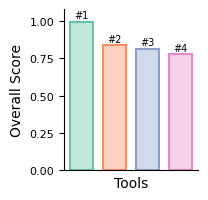

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

bar_alpha = 0.4
bar_lw = 1.5

methods = df_reset["Method"].tolist()
colors = dict(zip(methods, sns.color_palette("Set2", len(methods))))

fig, ax = plt.subplots(figsize=mm_to_inches([50, 50]))

xpos = np.arange(len(methods))
bars = ax.bar(xpos, df_reset["Score"].values,
              color=[colors[m] for m in methods], width=0.7)

for p in bars:
    r, g, b = p.get_facecolor()[:3]
    p.set_edgecolor((r, g, b, 1))
    p.set_facecolor((r, g, b, bar_alpha))
    p.set_linewidth(bar_lw)

for xi, score, rank in zip(xpos, df_reset["Score"].values, df_reset["Ranking"]):
    ax.text(xi, score + 0.01, f"#{int(rank)}",
            ha="center", va="bottom", fontsize=7)

ax.set_ylabel("Overall Score", fontsize=10)
ax.set_xlabel("Tools", fontsize=10)
ax.set_xticks([])
ax.set_ylim(0, 1.08)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
ax.tick_params(axis="y", labelsize=8)
ax.spines[["top", "right"]].set_visible(False)

fig.subplots_adjust(left=0.3, bottom=0.15, right=0.98, top=0.97)

fig.savefig(fig_dir / "barplot_overall_score.pdf", dpi=300, pad_inches=0)